# Metadata Model - Fixed Patient-Level Split

**Acknowledgement**

This is adapted from Thomas's original metadata modelling notebook (03_metadata_model_d1.ipynb on the thomas branch). The preprocessing pipelines, model definitions and core analysis is based on his work. 

This adaptation replaces five-fold evaluation with the project's fixed patient-level training and validation splits. Results and interpretations have been updated, and validation probabilities have been exported for future comparison and application with the image model.

**Overview**

Five metadata models were fitted to **5,740 training images** and evaluated on **1,124 validation images** from separate patients. Validation contains only **18 melanoma images**, so model rankings are uncertain.

Metadata-only performance is weak on this split. Spline logistic regression has the highest average precision among the five main models (**0.0216**, compared with a prevalence reference of **0.0160**), while random forest has the highest ROC-AUC (**0.5252**). The prevalence dummy has the lowest log loss and Brier score.

All five models' validation probabilities are exported for comparison with aligned image-model predictions. No final metadata model is selected here, and test outcomes are not used during development.


## Purpose and evaluation design

This notebook establishes metadata-only baselines for image-level melanoma classification. It uses the existing patient-level assignments in `data/derived/splits/subset_split_index.csv`; it does not create new splits.

| Split | Images | Patients | Melanoma images | Melanoma prevalence |
|---|---:|---:|---:|---:|
| Training | 5,740 | 358 | 110 | 1.92% |
| Validation | 1,124 | 64 | 18 | 1.60% |

The predictors are **sex**, **approximate age** and **anatomical site**. The target is image-level melanoma status (`target == 1`). Identifiers are retained for checks and prediction alignment; outcome-revealing columns such as `diagnosis` and `benign_malignant` are excluded from model inputs.

Models and learned preprocessing are fitted using the training split. Model comparisons, feature ablations and exploratory threshold selection use the validation split. All images from a patient remain in one split.

Test patient IDs are used only to check separation from training and validation patients. Test labels and predictions are not used for model fitting, model selection or threshold selection.


### Models compared

| Model | Purpose | Predictor representation |
|---|---|---|
| Prevalence dummy | Constant-probability baseline | Predicts the training melanoma prevalence for every validation image |
| Standard logistic regression | Simple additive baseline | One-hot-encoded age values, sex and anatomical site |
| Spline logistic regression | Additive model with a smooth age relationship | Cubic spline age terms plus one-hot-encoded sex and anatomical site |
| Random forest | Tree ensemble for nonlinear patterns and interactions | One-hot-encoded metadata |
| XGBoost | Boosted tree model for nonlinear patterns and interactions | One-hot-encoded metadata |

The spline model uses four knots placed at training-age quantiles. This allows a smooth, nonlinear relationship with age while keeping the age representation relatively compact. Its performance is assessed alongside the other models; using a spline does not establish that it is the best model.

## Setup and data preparation

### Import dependencies and set project paths

The setup cell locates the project root through `pyproject.toml`, defines the split-index input and output paths, and sets the predictor columns and model labels. Run the notebook from within the project so these relative paths resolve correctly.

The following cells define preprocessing pipelines, validation prediction helpers and evaluation metrics directly in the notebook.

In [53]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)
from xgboost import XGBClassifier

# Render notebook figures as high-resolution PNG images.
set_matplotlib_formats("retina")
plt.rcParams["figure.dpi"] = 120


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())

SPLIT_INDEX_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "splits"
    / "subset_split_index.csv"
)

PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "results"
    / "predictions"
    / "metadata_validation_predictions.csv"
)

CURVES_PATH = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / "metadata_validation_curves.png"
)

FEATURE_COLUMNS = [
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
]
MODEL_LABELS = {
    "dummy": "Prevalence dummy",
    "logistic": "Standard logistic regression",
    "spline_logistic": "Spline logistic regression",
    "random_forest": "Random forest",
    "xgboost": "XGBoost",
}

print(f"Split index: {SPLIT_INDEX_PATH}")

Split index: C:\Users\madis\Documents\ADS2002-Melanoma\data\derived\splits\subset_split_index.csv


### Define preprocessing and model pipelines

The standard logistic and tree models one-hot encode all three predictors, including the recorded age values. Categories not seen during training are handled by the encoder without fitting it again on validation data.

For spline logistic regression, age is converted to numeric values. Missing or non-numeric ages are replaced with the **training median**, then transformed using cubic splines and scaled. Sex and anatomical site remain categorical.

All learned preprocessing stays inside each model pipeline and is fitted only on the training split. The fixed `Unknown` category used for missing categorical values does not depend on outcome labels.

In [54]:
def convert_age_to_numeric(values):
    '''Convert age strings to numbers without changing the source data.'''
    return pd.DataFrame(values).apply(pd.to_numeric, errors="coerce")


def build_preprocessor(features, smooth_age=False):
    '''Keep preprocessing inside the model so it is fitted on training data only'''
    features = list(features)

    if not smooth_age:
        return ColumnTransformer(
            [("categorical", OneHotEncoder(handle_unknown="ignore"), features)],
            remainder="drop",
        )

    transformers = []
    if "age_approx" in features:
        age_steps = Pipeline(
            [
                (
                    "to_numeric",
                    FunctionTransformer(
                        convert_age_to_numeric,
                        feature_names_out="one-to-one",
                    ),
                ),
                ("imputer", SimpleImputer(strategy="median")),
                (
                    "spline",
                    SplineTransformer(
                        n_knots=4,
                        degree=3,
                        knots="quantile",
                        include_bias=False,
                    ),
                ),
                ("scaler", StandardScaler()),
            ]
        )
        transformers.append(("smooth_age", age_steps, ["age_approx"]))

    categorical_features = [
        feature
        for feature in ("sex", "anatom_site_general_challenge")
        if feature in features
    ]
    if categorical_features:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features,
            )
        )
    return ColumnTransformer(transformers, remainder="drop")


def logistic_regression():
    '''Use the same simple logistic classifier wherever it is needed.'''
    return LogisticRegression(
        C=1.0, solver="liblinear", max_iter=1_000, random_state=42
    )


def make_metadata_pipeline(classifier, features, smooth_age=False):
    '''Keep preprocessing inside the model so each fold fits it independently.'''
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(features, smooth_age)),
            ("classifier", classifier),
        ]
    )




### Define validation prediction and metric helpers

The prediction helper clones an estimator, fits it on the training split and returns melanoma probabilities for the patient-disjoint validation split. The metric helper calculates ROC-AUC, average precision, log loss and Brier score from those validation probabilities.

In [55]:
def fit_and_predict_validation(
    training_data,
    validation_data,
    estimator,
    features,
):
    """Fit on the training split and predict the validation split."""

    fitted_model = clone(estimator)

    fitted_model.fit(
        training_data[features],
        training_data["target"],
    )

    positive_class_position = list(
        fitted_model.classes_
    ).index(1)

    probabilities = fitted_model.predict_proba(
        validation_data[features]
    )[:, positive_class_position]

    return fitted_model, pd.Series(
        probabilities,
        index=validation_data.index,
    )


def binary_probability_metrics(targets, probabilities):
    return {
        "roc_auc": roc_auc_score(targets, probabilities),
        "average_precision": average_precision_score(
            targets,
            probabilities,
        ),
        "log_loss": log_loss(
            targets,
            probabilities,
            labels=[0, 1],
        ),
        "brier_score": brier_score_loss(
            targets,
            probabilities,
        ),
    }

### Load the split index and verify patient separation

Load the existing split index, check that the required columns are present and represent missing metadata with a fixed `Unknown` value. Select the training and validation rows using `model_split`.

The assertions verify the expected training and validation image and melanoma counts, and confirm that training, validation and test patient IDs do not overlap. These checks preserve the shared split used by the image pipeline.

In [56]:
metadata = pd.read_csv(
    SPLIT_INDEX_PATH,
    dtype={"age_approx": "string"},
)

required_columns = {
    "image_name",
    "patient_id",
    "target",
    "model_split",
    *FEATURE_COLUMNS,
}

missing_columns = required_columns - set(metadata.columns)

assert not missing_columns, (
    f"Missing columns: {sorted(missing_columns)}"
)

# Fixed missing-value categories do not use information
# from validation or test outcomes.
metadata["sex"] = metadata["sex"].fillna("Unknown")
metadata["age_approx"] = metadata["age_approx"].fillna("Unknown")
metadata["anatom_site_general_challenge"] = (
    metadata["anatom_site_general_challenge"]
    .fillna("Unknown")
)

train = metadata.loc[
    metadata["model_split"].eq("train")
].copy()

validation = metadata.loc[
    metadata["model_split"].eq("validation")
].copy()

# Do not inspect test labels during model development.
test_patient_ids = set(
    metadata.loc[
        metadata["model_split"].eq("test"),
        "patient_id",
    ]
)

train_patient_ids = set(train["patient_id"])
validation_patient_ids = set(validation["patient_id"])

assert train_patient_ids.isdisjoint(validation_patient_ids)
assert train_patient_ids.isdisjoint(test_patient_ids)
assert validation_patient_ids.isdisjoint(test_patient_ids)

assert len(train) == 5740
assert len(validation) == 1124
assert train["target"].sum() == 110
assert validation["target"].sum() == 18

print(f"Training images: {len(train):,}")
print(f"Validation images: {len(validation):,}")
print(f"Training patients: {train['patient_id'].nunique():,}")
print(
    f"Validation patients: "
    f"{validation['patient_id'].nunique():,}"
)

Training images: 5,740
Validation images: 1,124
Training patients: 358
Validation patients: 64


## Validation results

### 1. Fit the models and generate validation probabilities

Each model is fitted on the 5,740 training images and generates probabilities for the same 1,124 validation images. Predictions are stored with `image_name`, `patient_id` and `target` so they can be aligned with image-model predictions later.

The checks below require every model probability to be present and between 0 and 1. No test predictions are generated.

In [57]:
estimators = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": make_metadata_pipeline(logistic_regression(), FEATURE_COLUMNS),
    "spline_logistic": make_metadata_pipeline(
        logistic_regression(), FEATURE_COLUMNS, smooth_age=True
    ),
    "random_forest": make_metadata_pipeline(
        RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1
        ),
        FEATURE_COLUMNS,
    ),
    "xgboost": make_metadata_pipeline(
        XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.05,
            objective="binary:logistic", eval_metric="logloss",
            random_state=42, n_jobs=-1,
        ),
        FEATURE_COLUMNS,
    ),
}

validation_predictions = validation[
    ["image_name", "patient_id", "target"]
].copy()

fitted_models = {}

for model_name, estimator in estimators.items():

    fitted_model, probabilities = (
        fit_and_predict_validation(
            train,
            validation,
            estimator,
            FEATURE_COLUMNS,
        )
    )

    fitted_models[model_name] = fitted_model

    validation_predictions[
        f"{model_name}_probability"
    ] = probabilities.to_numpy()

probability_columns = [
    f"{model_name}_probability"
    for model_name in estimators
]

assert validation_predictions[
    probability_columns
].notna().all().all()

assert validation_predictions[
    probability_columns
].apply(
    lambda values: values.between(0, 1).all()
).all()

print(
    f"Validation predictions created for "
    f"{len(validation_predictions):,} images."
)


Validation predictions created for 1,124 images.


### 2. Compare ranking and probability quality

The table compares all five models on the fixed validation split. Average precision is the main ranking summary, with ROC-AUC as a complementary measure. Log loss and Brier score assess probability quality relative to the constant prevalence baseline.

All metrics are calculated per image. Patients with more images therefore contribute more to these scores.


In [58]:
metric_records = []

for model_name in estimators:

    metrics = binary_probability_metrics(
        validation_predictions["target"],
        validation_predictions[
            f"{model_name}_probability"
        ],
    )

    metric_records.append({
        "model": model_name,
        **metrics,
    })

validation_metrics = (
    pd.DataFrame(metric_records)
    .set_index("model")
    .rename(index=MODEL_LABELS)
)

validation_metrics.round(4)

,roc_auc,average_precision,log_loss,brier_score
model,,,,
Prevalence dummy,0.5000,0.0160,0.0824,0.0158
Standard logistic regression,0.4414,0.0171,0.0880,0.0161
Spline logistic regression,0.4945,0.0216,0.0884,0.0162
Random forest,0.5252,0.0198,0.0847,0.0160
XGBoost,0.4738,0.0182,0.0878,0.0161


**How to read the metrics**

- **Average precision (AP):** summarises precision across recall levels; higher is better. The constant-score reference is the validation melanoma prevalence, **18 / 1,124 = 0.0160**, or approximately **1.60%**.
- **ROC-AUC:** measures how often a melanoma image is ranked above a benign image, giving half credit to tied scores. A value of 0.5 indicates chance-level ranking.
- **Log loss:** assesses predicted probabilities and penalises confident errors. Lower is better.
- **Brier score:** measures the mean squared difference between predicted probabilities and binary outcomes. Lower is better.

The dummy predicts the **training** prevalence (approximately 1.92%) for every validation image. Its validation AP is nevertheless **0.0160**, because AP for constant scores depends on the prevalence in the evaluated sample.

In the saved run, spline logistic regression has the highest AP among the five main models (**0.0216**), while random forest has the highest ROC-AUC (**0.5252**). All four learned models have higher log loss and Brier score than the dummy.

These results show weak and inconsistent validation performance. With only **18 melanoma images**, small differences do not establish a reliable model ranking. No final metadata model is selected from this table.


### 3. Compare ROC and precision–recall curves

Each learned model appears on its own row to keep the curves readable.

- The grey diagonal is the chance-level ROC reference.
- The grey horizontal line is the validation melanoma prevalence, approximately **1.60%**.
- The precision axis is zoomed to **0–10%**. This changes only the display; AP is still calculated from the complete predictions.

The conventional precision–recall endpoint at precision 1 and recall 0 lies outside the zoomed view. It is a plotting endpoint and not evidence of perfect predictions.

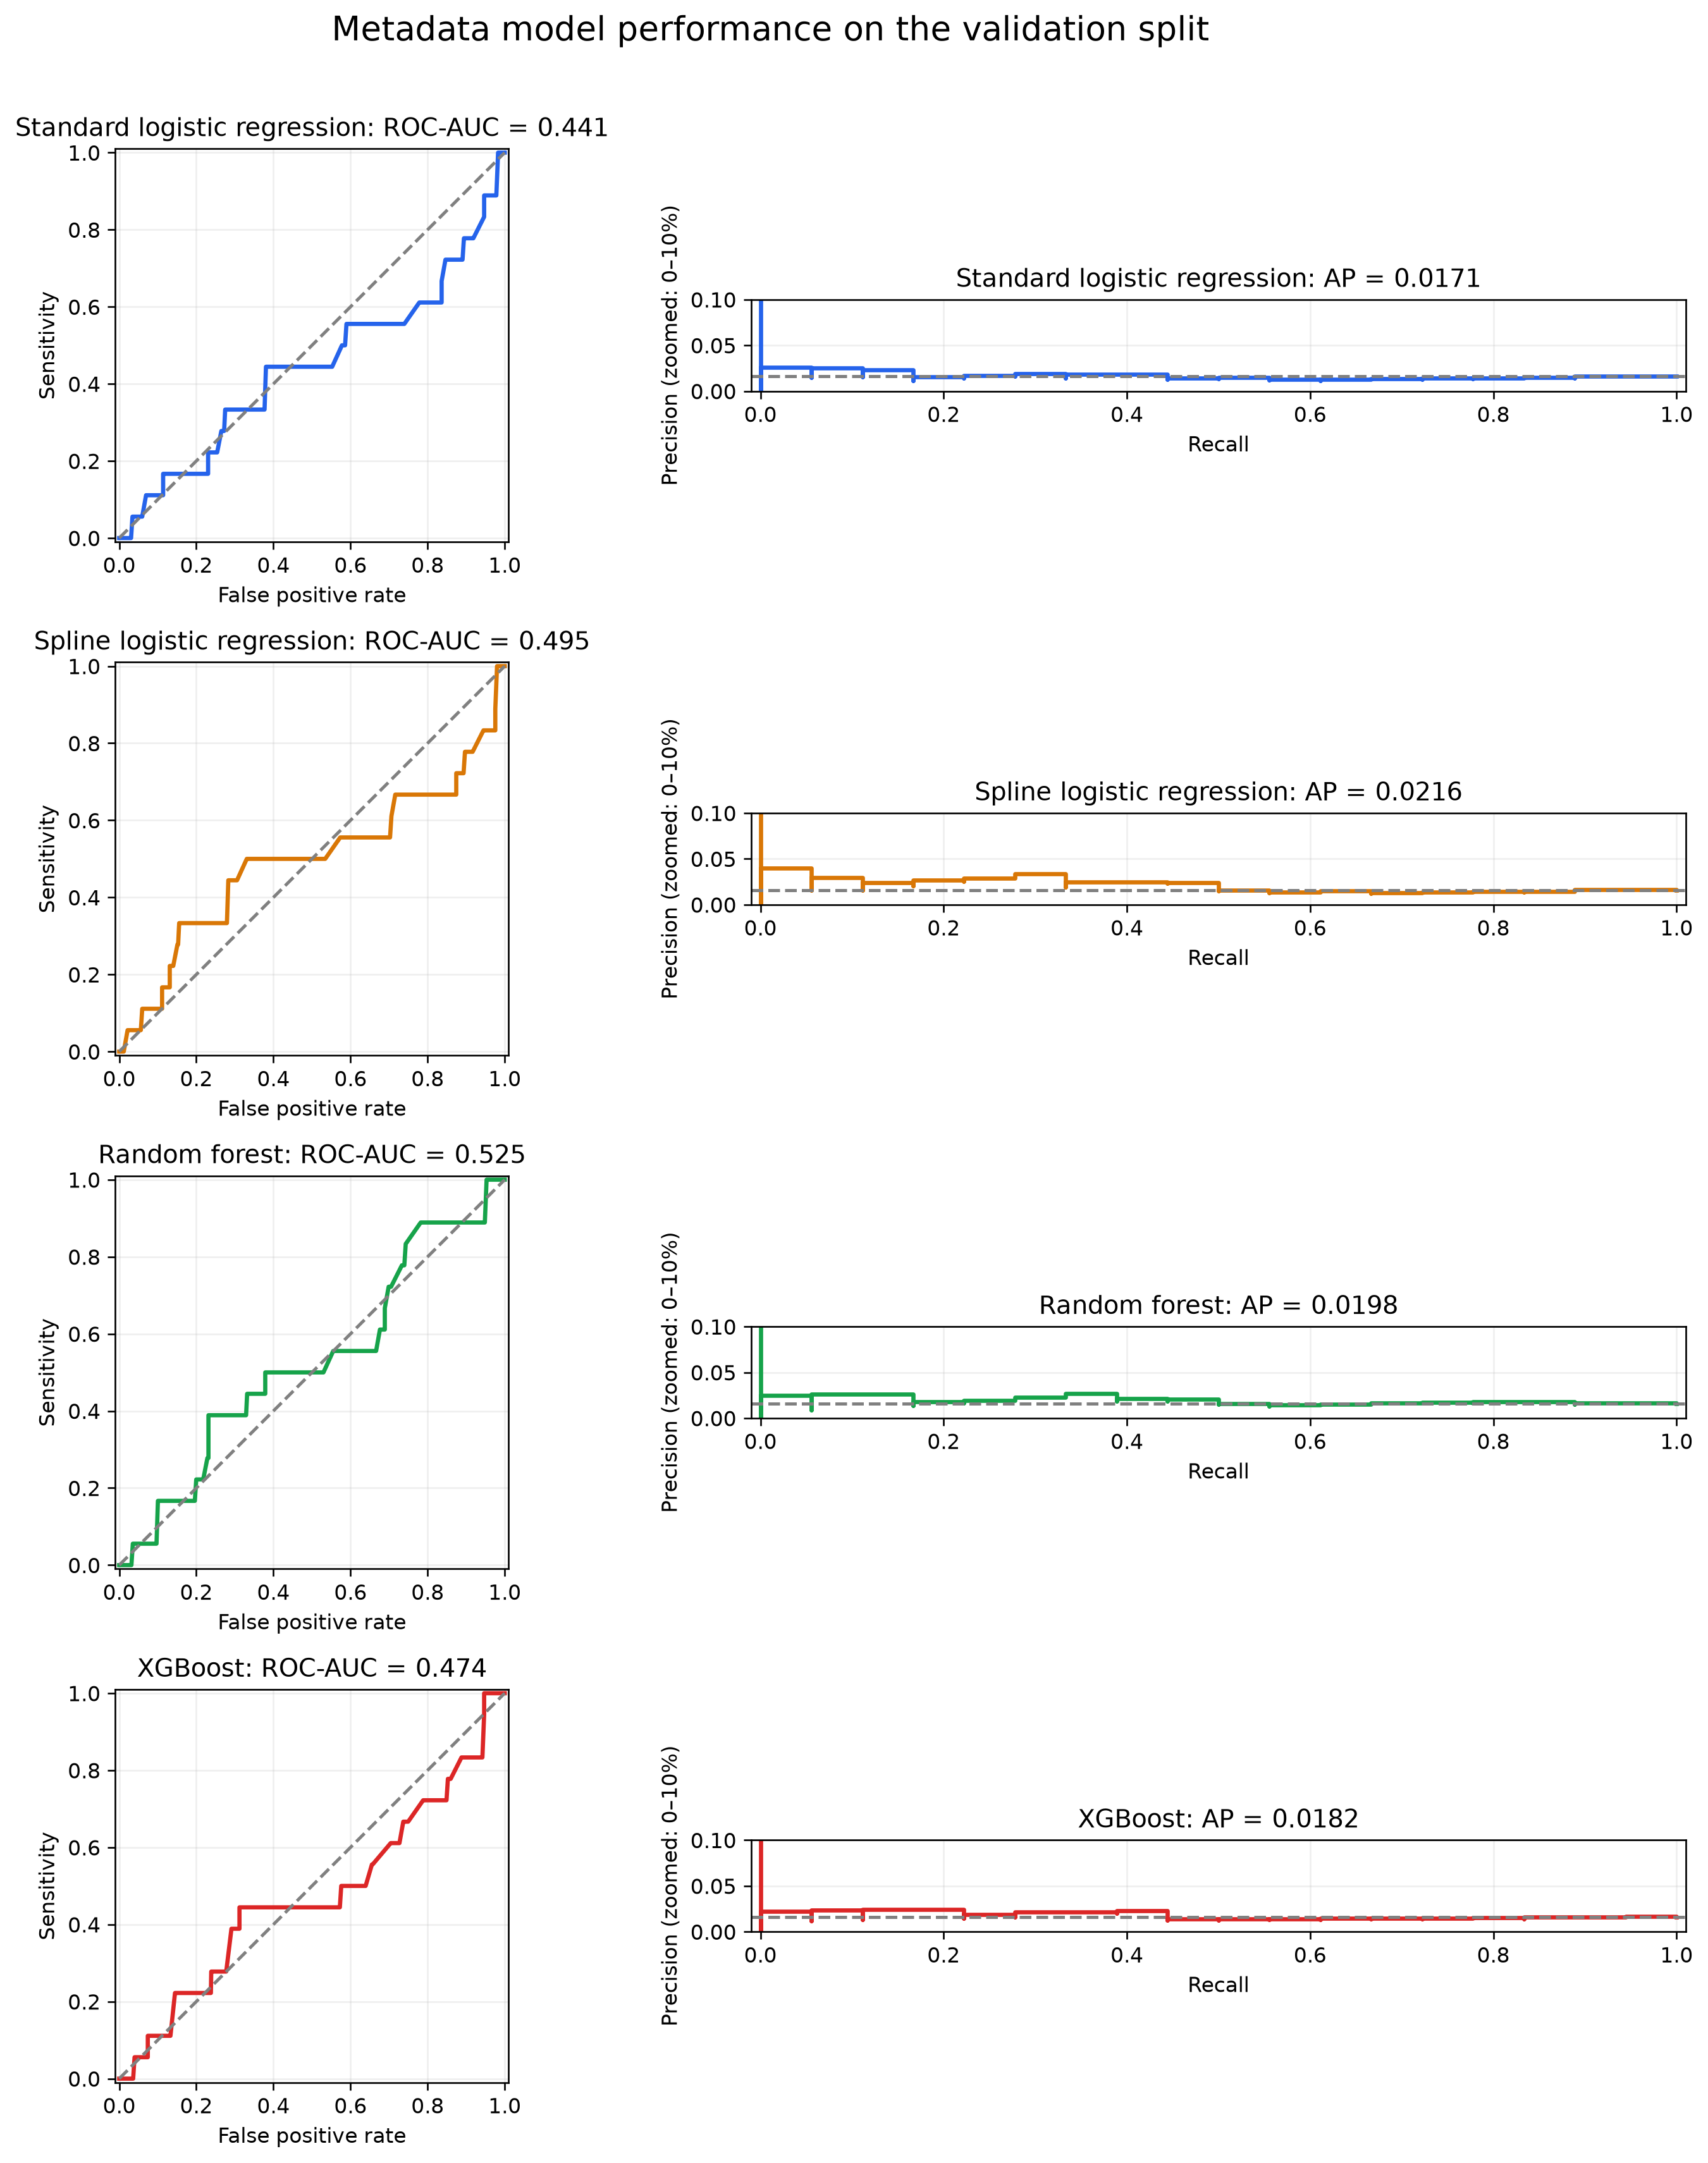

In [59]:
learned_model_names = [
    "logistic",
    "spline_logistic",
    "random_forest",
    "xgboost",
]

colours = {
    "logistic": "#2563EB",
    "spline_logistic": "#D97706",
    "random_forest": "#16A34A",
    "xgboost": "#DC2626",
}

fig, axes = plt.subplots(
    len(learned_model_names),
    2,
    figsize=(12.5, 14.5),
)

for row, model_name in enumerate(learned_model_names):

    probability_column = f"{model_name}_probability"
    model_label = MODEL_LABELS[model_name]
    roc_axis, precision_recall_axis = axes[row]

    RocCurveDisplay.from_predictions(
        validation_predictions["target"],
        validation_predictions[probability_column],
        name=model_label,
        curve_kwargs={"color": colours[model_name], "linewidth": 2,},
        ax=roc_axis,
    )

    roc_axis.plot(
        [0, 1],
        [0, 1],
        color="grey",
        linestyle="--",
    )

    roc_axis.set_title(
        f"{model_label}: "
        f"ROC-AUC = "
        f"{validation_metrics.loc[model_label, 'roc_auc']:.3f}"
    )

    PrecisionRecallDisplay.from_predictions(
        validation_predictions["target"],
        validation_predictions[probability_column],
        name=model_label,
        curve_kwargs={"color": colours[model_name],"linewidth": 2,},
        ax=precision_recall_axis,
    )

    precision_recall_axis.axhline(
        validation["target"].mean(),
        color="grey",
        linestyle="--",
        label="Validation prevalence",
    )

    precision_recall_axis.set_title(
        f"{model_label}: "
        f"AP = "
        f"{validation_metrics.loc[model_label, 'average_precision']:.4f}"
    )

    for axis in (roc_axis, precision_recall_axis):
        axis.grid(alpha=0.2)

    precision_recall_axis.set_ylim(0, 0.10)
    precision_recall_axis.set_xlabel("Recall")
    precision_recall_axis.set_ylabel("Precision (zoomed: 0–10%)")

    roc_axis.set_xlabel("False positive rate")
    roc_axis.set_ylabel("Sensitivity")

    # Model names and scores are already in the titles.
    for axis in (roc_axis, precision_recall_axis):
        legend = axis.get_legend()
        if legend is not None:
            legend.remove()

fig.suptitle(
    "Metadata model performance on the validation split",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

CURVES_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    CURVES_PATH,
    dpi=320,
    bbox_inches="tight",
)

plt.show()

### 4. Compare predictor combinations with feature ablation

,Features,roc_auc,average_precision,AP gain vs dummy,log_loss,brier_score
Feature set,,,,,,
Sex only,sex,0.5806,0.0193,0.0033,0.0818,0.0157
Age only,age_approx,0.5009,0.0279,0.0119,0.0889,0.0162
Site only,anatom_site_general_challenge,0.4668,0.0269,0.0109,0.0823,0.0157
Sex + age,"sex, age_approx",0.5112,0.0264,0.0104,0.0887,0.0162
Sex + site,"sex, anatom_site_general_challenge",0.5582,0.0322,0.0162,0.0817,0.0157
Age + site,"age_approx, anatom_site_general_challenge",0.4898,0.0216,0.0055,0.0887,0.0162
All features,"sex, age_approx, anatom_site_general_challenge",0.4945,0.0216,0.0056,0.0884,0.0162


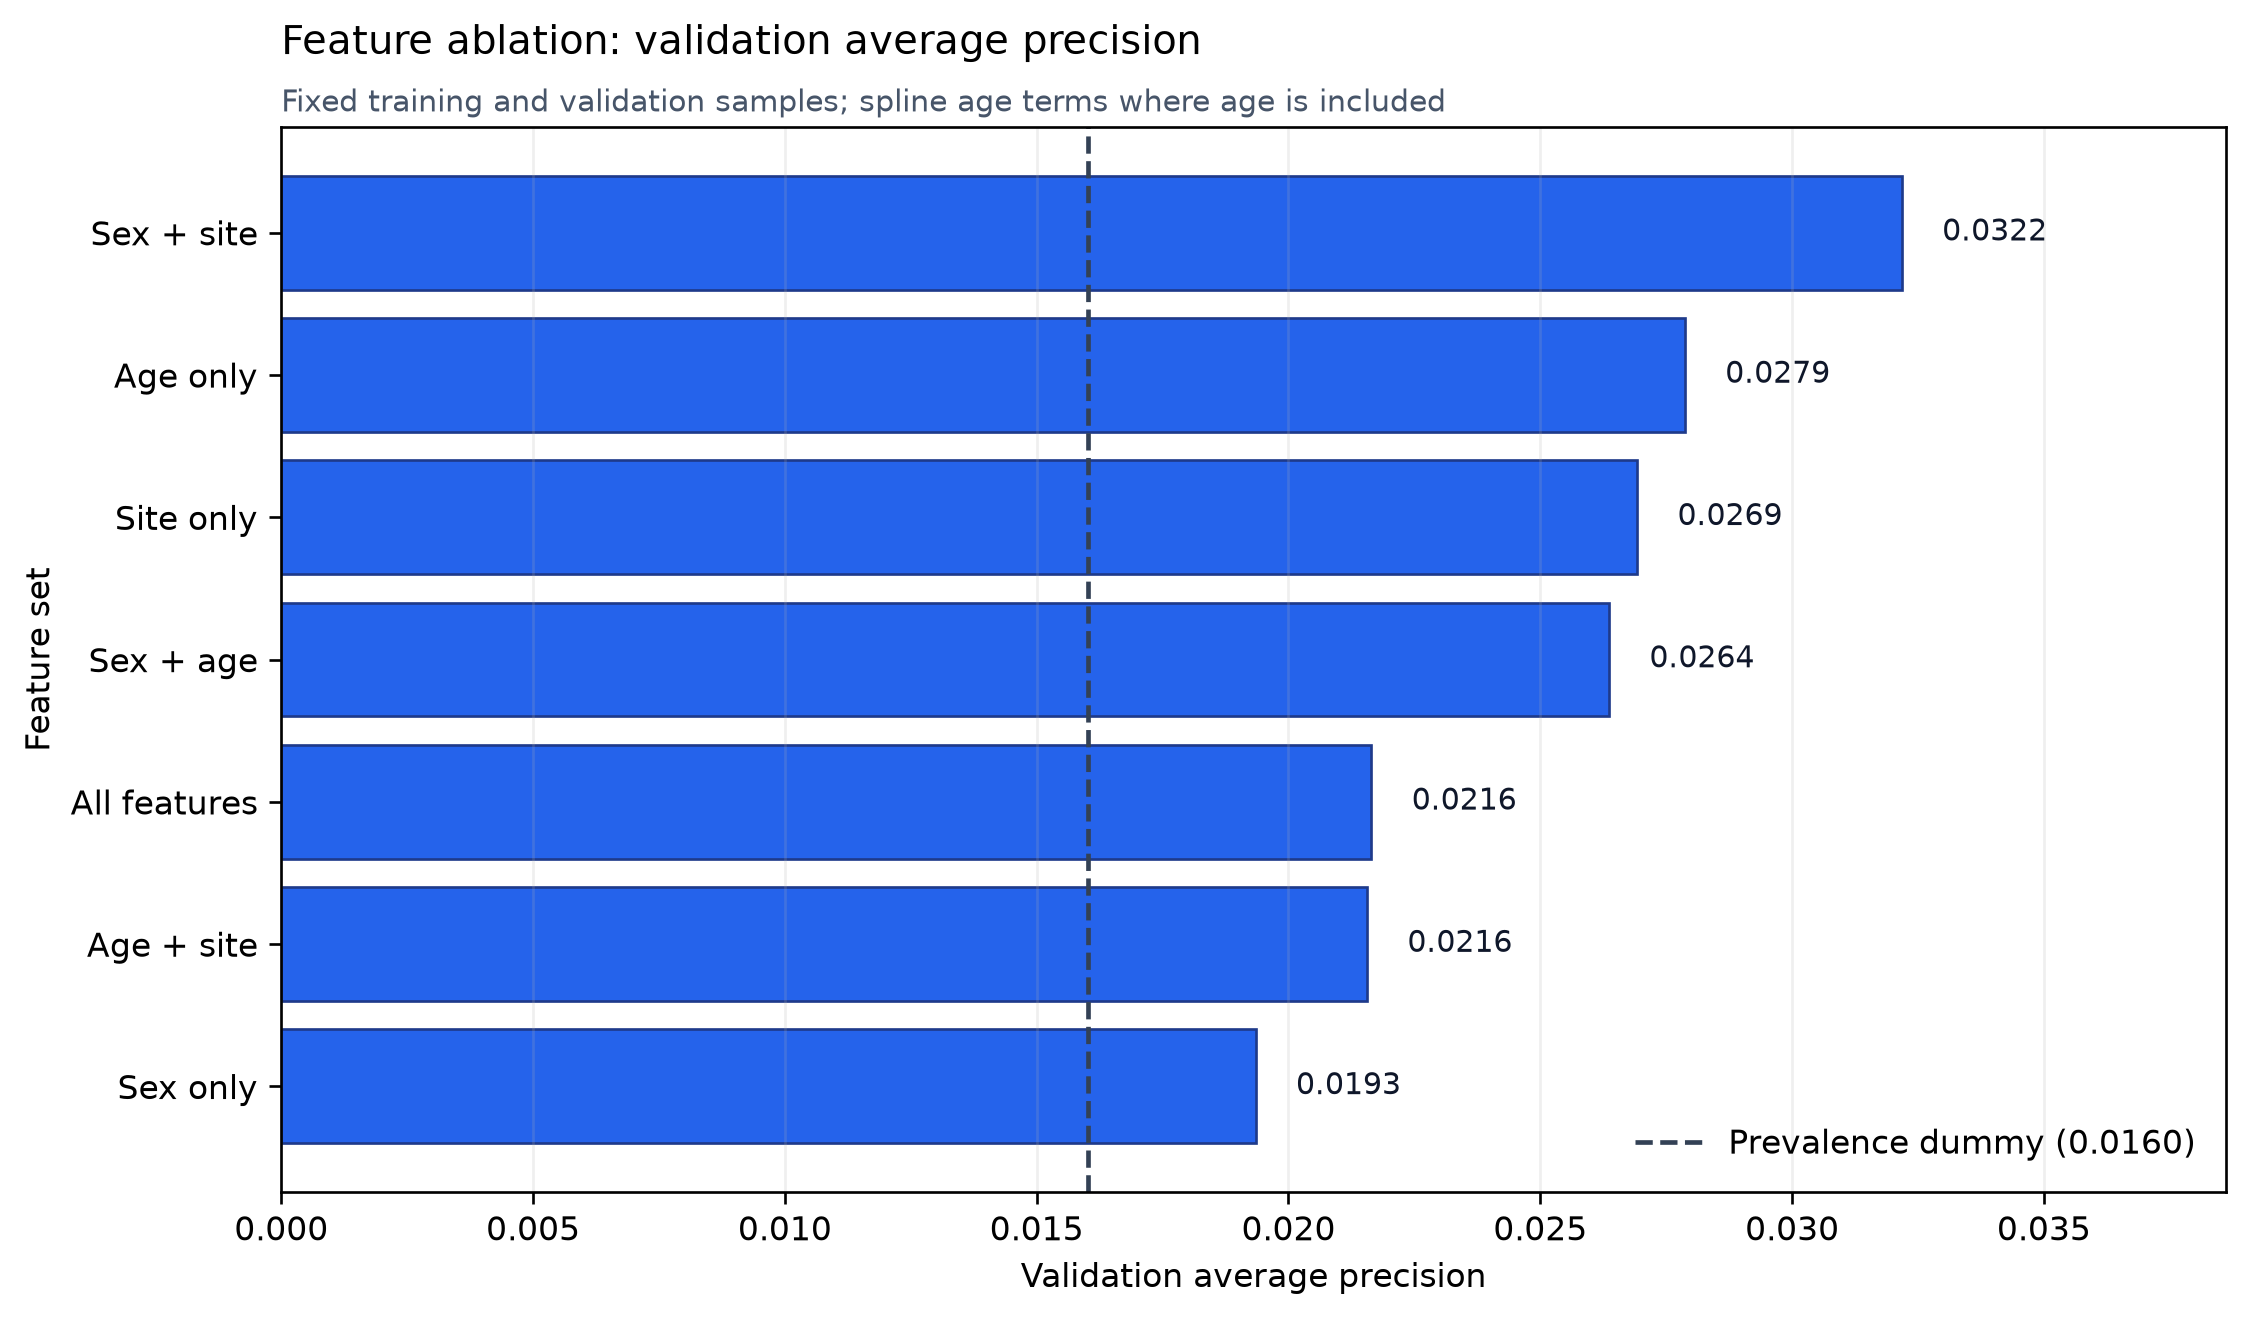

In [60]:
ablation_feature_sets = {
    "Sex only": ["sex"],
    "Age only": ["age_approx"],
    "Site only": ["anatom_site_general_challenge"],
    "Sex + age": ["sex", "age_approx"],
    "Sex + site": ["sex", "anatom_site_general_challenge"],
    "Age + site": ["age_approx", "anatom_site_general_challenge"],
    "All features": FEATURE_COLUMNS,
}

ablation_rows = []
full_feature_ablation_probabilities = None
for feature_set_name, feature_set_columns in ablation_feature_sets.items():
    ablation_model = make_metadata_pipeline(
        logistic_regression(),
        feature_set_columns,
        smooth_age=True,
    )

    ablation_model.fit(
        train[feature_set_columns],
        train["target"],
    )

    ablation_probabilities = (
        ablation_model.predict_proba(
            validation[feature_set_columns]
        )[:, 1]
    )

    ablation_metrics = binary_probability_metrics(
        validation["target"],
        ablation_probabilities,
    )
    ablation_rows.append(
        {
            "Feature set": feature_set_name,
            "Features": ", ".join(feature_set_columns),
            **ablation_metrics,
        }
    )
    if feature_set_name == "All features":
        full_feature_ablation_probabilities = ablation_probabilities



ablation_results = pd.DataFrame(ablation_rows).set_index("Feature set")
dummy_average_precision = validation_metrics.loc[
    "Prevalence dummy",
    "average_precision",
]
ablation_results["AP gain vs dummy"] = (
    ablation_results["average_precision"] - dummy_average_precision
)

display(
    ablation_results[
        ["Features", "roc_auc", "average_precision", "AP gain vs dummy", "log_loss", "brier_score"]
    ].round(4)
)

plot_data = ablation_results.sort_values("average_precision")
fig, axis = plt.subplots(figsize=(9.5, 5.6))
bars = axis.barh(
    plot_data.index,
    plot_data["average_precision"],
    color="#2563EB",
    edgecolor="#1E3A8A",
    linewidth=0.8,
)
axis.axvline(
    dummy_average_precision,
    color="#334155",
    linestyle="--",
    linewidth=1.4,
    label=f"Prevalence dummy ({dummy_average_precision:.4f})",
)

for bar, value in zip(bars, plot_data["average_precision"]):
    axis.text(
        value + 0.0008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=9,
        color="#0F172A",
    )

axis.set_xlim(0, plot_data["average_precision"].max() * 1.20)
axis.set_xlabel("Validation average precision")
axis.set_ylabel("Feature set")
axis.set_title("Feature ablation: validation average precision", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Fixed training and validation samples; spline age terms where age is included",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.legend(frameon=False, loc="lower right")
axis.grid(axis="x", alpha=0.20)
fig.tight_layout()
plt.show()

**Feature-ablation interpretation**

The **sex-and-site** model has the highest validation AP among the tested combinations (**0.0322**), while **sex alone** has the highest ROC-AUC (**0.5806**). Age-only and site-only models also exceed the prevalence reference in AP. Sex-and-site has the lowest log loss in the ablation table (**0.0817**), slightly below the dummy's **0.0824**.

These rankings differ from the earlier five-fold analysis, where age supplied the strongest signal. That earlier analysis used different training and held-out predictions, so its scores are not directly comparable with this fixed-split run.

Only 18 validation images are melanoma-positive, and several feature combinations have been compared on those same images. Treat the findings as exploratory; they do not justify selecting sex-and-site as the final model by themselves.

### 5. Describe the fitted age relationship using training data

Individual spline coefficients describe mathematical basis functions and are difficult to interpret directly. Instead, the plot shows the model's average predicted melanoma probability at each recorded age.

The spline model is fitted only to the **training split**. For each age, every training row is assigned that age while its sex and site values are retained; the resulting probabilities are averaged. The observed points show melanoma prevalence within the corresponding training-age groups, with point size proportional to the number of images.

This is a descriptive view of the fitted model and training data. It does not measure held-out performance or a causal effect of age; predictive performance is assessed using the validation results above.


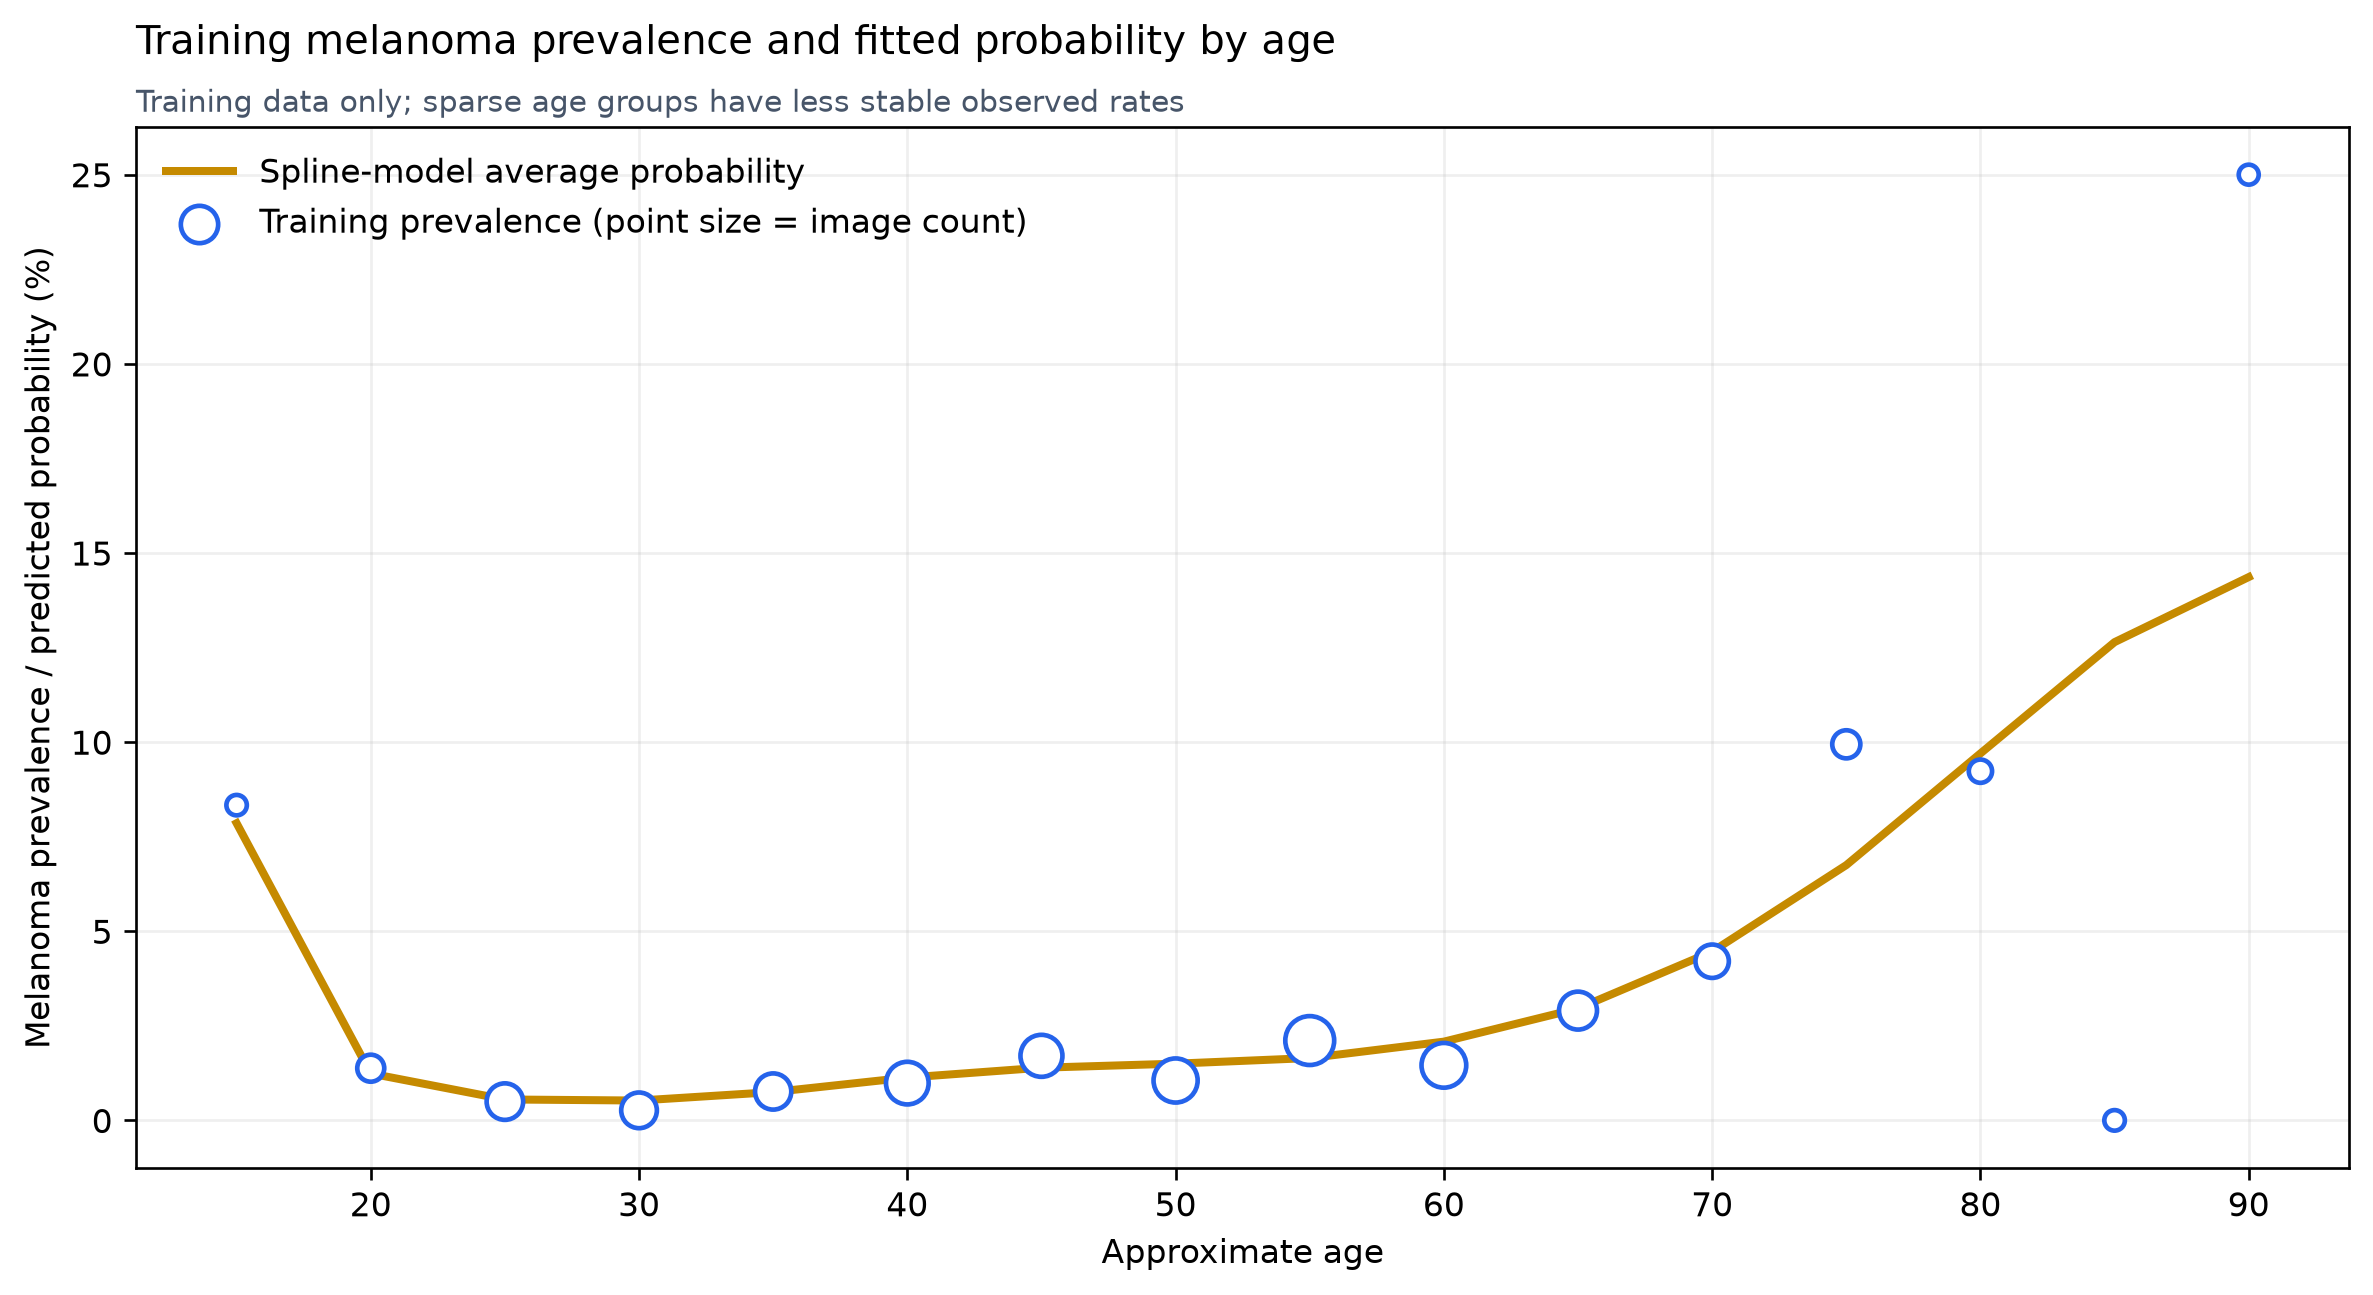

,age,images,malignant_images,Observed prevalence (%),Model-implied average risk (%)
0,15.0,12,1,8.33,7.86
1,20.0,145,2,1.38,1.24
2,25.0,403,2,0.50,0.55
3,30.0,377,1,0.27,0.52
4,35.0,393,3,0.76,0.75
5,40.0,609,6,0.99,1.13
6,45.0,586,10,1.71,1.39
7,50.0,664,7,1.05,1.50
8,55.0,853,18,2.11,1.65
9,60.0,687,10,1.46,2.08


In [61]:
fitted_spline_model = make_metadata_pipeline(
    logistic_regression(), FEATURE_COLUMNS, smooth_age=True
)
fitted_spline_model.fit(train[FEATURE_COLUMNS], train["target"])

age_values = sorted(pd.to_numeric(train["age_approx"], errors="coerce").dropna().unique())
marginal_age_rows = []
for age in age_values:
    age_scenario = train[FEATURE_COLUMNS].copy()
    age_scenario["age_approx"] = str(int(age))
    marginal_age_rows.append(
        {
            "age": int(age),
            "model_implied_average_risk": fitted_spline_model.predict_proba(age_scenario)[:, 1].mean(),
        }
    )

marginal_age_risk = pd.DataFrame(marginal_age_rows)
observed_age_risk = (
    train.assign(age=pd.to_numeric(train["age_approx"], errors="coerce"))
    .groupby("age", as_index=False)["target"]
    .agg(images="size", malignant_images="sum", observed_prevalence="mean")
)
age_interpretation = observed_age_risk.merge(marginal_age_risk, on="age", how="left")

fig, axis = plt.subplots(figsize=(10, 5.5))
axis.plot(
    age_interpretation["age"],
    age_interpretation["model_implied_average_risk"] * 100,
    color="#C58A00",
    linewidth=2.4,
    label="Spline-model average probability",
)
marker_sizes = 35 + 180 * age_interpretation["images"] / age_interpretation["images"].max()
axis.scatter(
    age_interpretation["age"],
    age_interpretation["observed_prevalence"] * 100,
    s=marker_sizes,
    facecolors="white",
    edgecolors="#2563EB",
    linewidths=1.4,
    label="Training prevalence (point size = image count)",
    zorder=3,
)
axis.set_xlabel("Approximate age")
axis.set_ylabel("Melanoma prevalence / predicted probability (%)")
axis.set_title("Training melanoma prevalence and fitted probability by age", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Training data only; sparse age groups have less stable observed rates",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.grid(alpha=0.20)
axis.legend(frameon=False)
fig.tight_layout()
plt.show()

display(
    age_interpretation.assign(
        **{
            "Observed prevalence (%)": age_interpretation["observed_prevalence"] * 100,
            "Model-implied average risk (%)": age_interpretation["model_implied_average_risk"] * 100,
        }
    )[
        ["age", "images", "malignant_images", "Observed prevalence (%)", "Model-implied average risk (%)"]
    ].round(2)
)

The fitted curve generally rises at older ages, but both the observed rate and the fitted curve also rise at the youngest recorded age. Sparse groups are especially unstable: the training group aged 15 contains only 12 images, and the group aged 90 contains only four.

The curve describes an association learned from this training sample. Its shape does not demonstrate useful ranking on new patients; the spline model's validation ROC-AUC is approximately 0.495 in this run.

### 6. Describe training prevalence by sex and anatomical site

The following table reports image counts, melanoma counts and unadjusted melanoma prevalence for each sex and anatomical-site category in the **training split**. It provides descriptive context for the fitted models.

In [62]:
def prevalence_by_category(frame, column, feature_label):
    summary = (
        frame.groupby(column, dropna=False)["target"]
        .agg(images="size", malignant_images="sum", prevalence="mean")
        .reset_index()
        .rename(columns={column: "Category"})
    )
    summary.insert(0, "Feature", feature_label)
    summary["Prevalence (%)"] = summary.pop("prevalence") * 100
    return summary.sort_values("Prevalence (%)", ascending=False)


category_prevalence = pd.concat(
    [
        prevalence_by_category(train, "sex", "Sex"),
        prevalence_by_category(
            train,
            "anatom_site_general_challenge",
            "Anatomical site",
        ),
    ],
    ignore_index=True,
)
category_prevalence.round({"Prevalence (%)": 2})

,Feature,Category,images,malignant_images,Prevalence (%)
0,Sex,male,2740,63,2.30
1,Sex,female,3000,47,1.57
2,Anatomical site,oral/genital,30,3,10.00
3,Anatomical site,head/neck,376,18,4.79
4,Anatomical site,Unknown,87,2,2.30
5,Anatomical site,upper extremity,914,20,2.19
6,Anatomical site,torso,2869,49,1.71
7,Anatomical site,lower extremity,1414,18,1.27
8,Anatomical site,palms/soles,50,0,0.00


These training rates are unadjusted for other predictors and count images rather than equally weighting patients. They do not establish independent or causal effects.

Small categories can produce extreme percentages: oral/genital contains three melanoma images out of 30, while palms/soles contains zero out of 50. A zero observed count does not establish zero risk, and rates from these groups should not be treated as equally precise as those from larger groups.


### 7. Select exploratory validation thresholds

At a probability threshold of **0.50**, all five models classify every validation image as benign in the saved run. This gives **1,106 true negatives**, **18 false negatives** and no true positives or false positives. It illustrates why the default threshold is uninformative for sensitivity here.

For a descriptive comparison, select a separate threshold for each learned model by maximising **balanced accuracy**, the mean of sensitivity and specificity, on the validation predictions. The dummy stays at 0.50 because its constant scores cannot rank images. Predictions at or above the threshold are classified as melanoma-positive.

Thresholds are both selected and assessed using the **same validation labels**, so the resulting performance is optimistic. These are exploratory trade-offs, not independent estimates of final-test performance or validated clinical operating points. With 18 melanoma images, one additional true positive changes sensitivity by approximately **5.6 percentage points**.


In [63]:
def select_balanced_accuracy_threshold(y_true, probabilities):
    candidates = np.unique(np.concatenate(([0.0], probabilities, [1.0])))
    scores = np.array(
        [
            balanced_accuracy_score(y_true, probabilities >= threshold)
            for threshold in candidates
        ]
    )
    best_indices = np.flatnonzero(np.isclose(scores, scores.max()))
    best_index = best_indices[np.argmin(np.abs(candidates[best_indices] - 0.50))]
    return float(candidates[best_index]), float(scores[best_index])


y_true = validation_predictions["target"].to_numpy()
selected_thresholds = {"dummy": 0.50}
threshold_rows = []
default_threshold_rows = []

for model_name in estimators:
    probabilities = validation_predictions[f"{model_name}_probability"].to_numpy()

    default_tn, default_fp, default_fn, default_tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": 0.50,
            "TN": default_tn,
            "FP": default_fp,
            "FN": default_fn,
            "TP": default_tp,
        }
    )

    if model_name == "dummy":
        threshold = 0.50
        balanced_accuracy = balanced_accuracy_score(y_true, probabilities >= threshold)
        threshold_type = "Fixed"
    else:
        threshold, balanced_accuracy = select_balanced_accuracy_threshold(
            y_true,
            probabilities,
        )
        selected_thresholds[model_name] = threshold
        threshold_type = "Exploratory validation-selected"

    threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "Threshold type": threshold_type,
            "Balanced accuracy": balanced_accuracy,
        }
    )

print("Default 0.50 threshold results:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))

threshold_summary = pd.DataFrame(threshold_rows).set_index("Model")
threshold_summary.round({"Threshold": 4, "Balanced accuracy": 4})

Default 0.50 threshold results:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,1106,0,18,0
Standard logistic regression,0.5,1106,0,18,0
Spline logistic regression,0.5,1106,0,18,0
Random forest,0.5,1106,0,18,0
XGBoost,0.5,1106,0,18,0


,Threshold,Threshold type,Balanced accuracy
Model,,,
Prevalence dummy,0.5000,Fixed,0.5000
Standard logistic regression,0.0187,Exploratory validation-selected,0.5319
Spline logistic regression,0.0259,Exploratory validation-selected,0.5889
Random forest,0.0236,Exploratory validation-selected,0.5787
XGBoost,0.0226,Exploratory validation-selected,0.5663


### 8. Compare validation confusion matrices

Each matrix shows counts and percentages at the threshold selected above. Percentages are normalised within each **actual** class:

- **TN** (true negatives) and **FP** (false positives) sum to 100% of actual benign images.
- **FN** (false negatives) and **TP** (true positives) sum to 100% of actual melanoma images.

The TP percentage is sensitivity, and the TN percentage is specificity. Precision in the results table instead uses predicted-positive images as its denominator: `TP / (TP + FP)`. When no images are predicted positive, the code reports precision as 0.0 by convention.

Colour intensity represents counts on a shared scale; the annotations provide the class-normalised percentages. Interpret all learned-model matrices as exploratory because their thresholds were selected on these validation data.


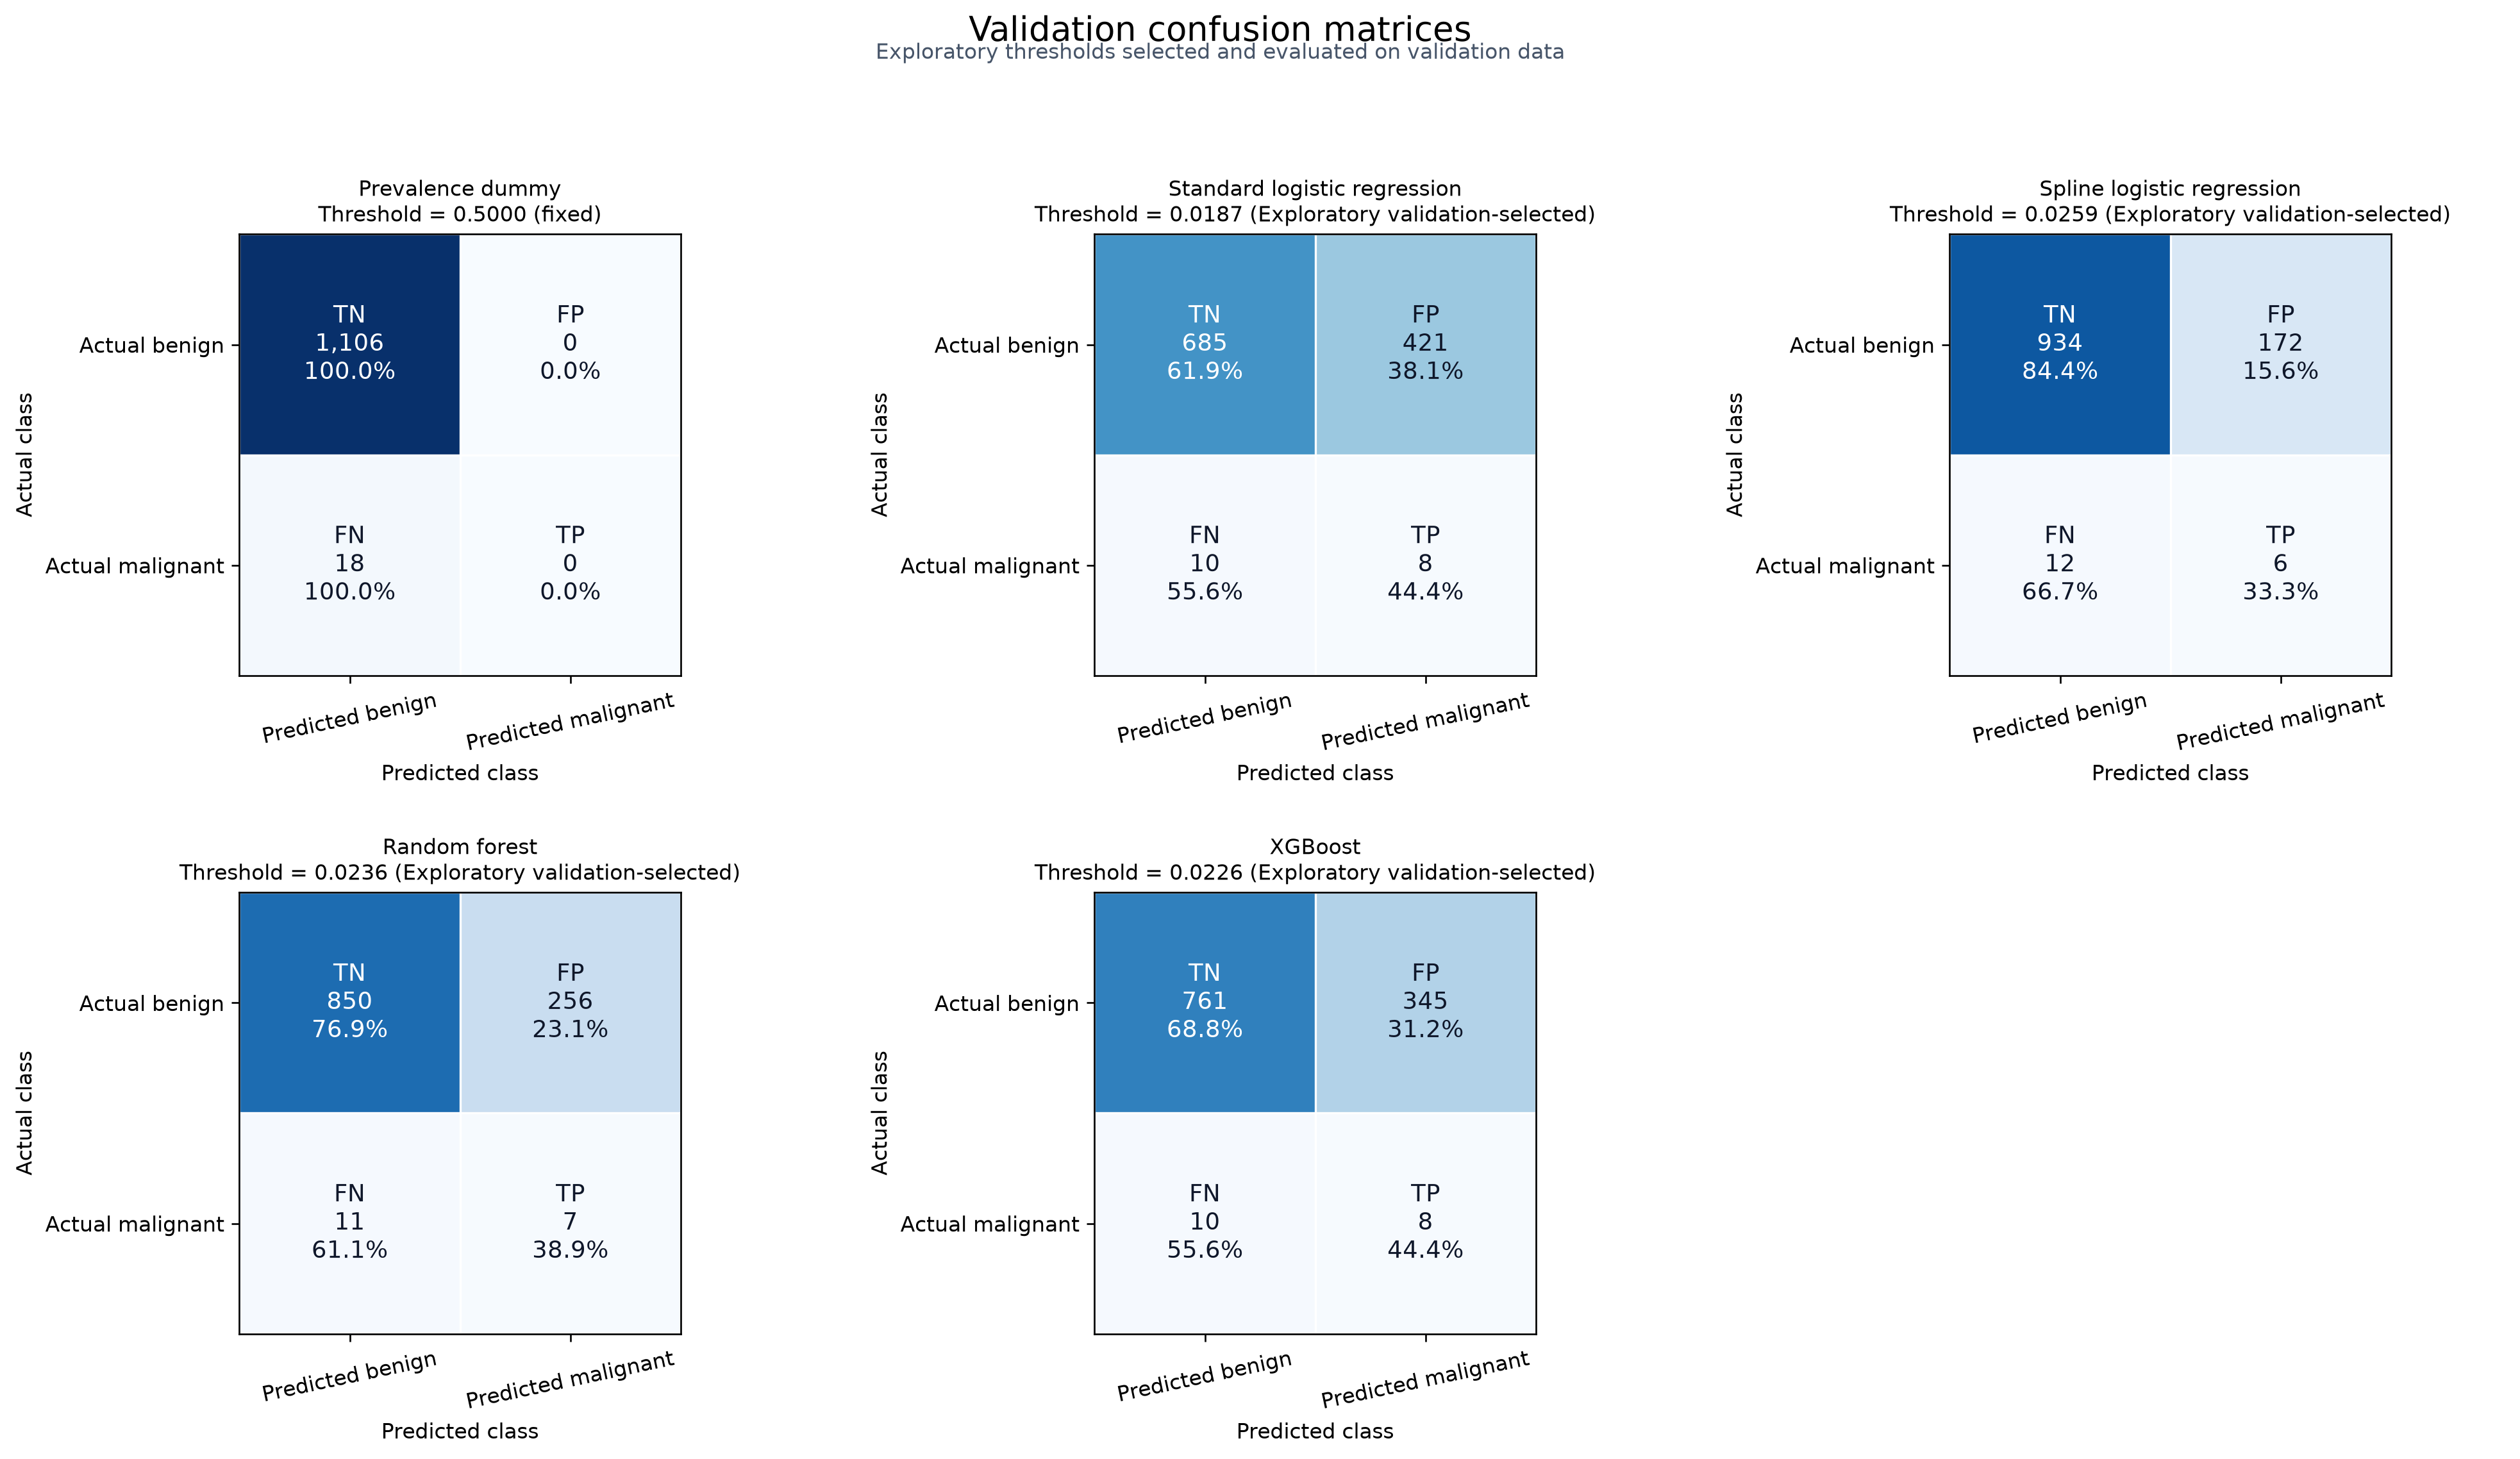

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,1106,100.0,0,0.0,18,100.0,0,0.0,0.0
Standard logistic regression,0.0187,685,61.9,421,38.1,10,55.6,8,44.4,1.9
Spline logistic regression,0.0259,934,84.4,172,15.6,12,66.7,6,33.3,3.4
Random forest,0.0236,850,76.9,256,23.1,11,61.1,7,38.9,2.7
XGBoost,0.0226,761,68.8,345,31.2,10,55.6,8,44.4,2.3


In [64]:
confusion_matrices = {}
for model_name in estimators:
    probabilities = validation_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= selected_thresholds[model_name]).astype(int)
    confusion_matrices[model_name] = confusion_matrix(
        y_true,
        predicted_labels,
        labels=[0, 1],
    )

shared_maximum = max(matrix.max() for matrix in confusion_matrices.values())
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
confusion_rows = []

for axis, model_name in zip(axes.flat, estimators):
    threshold = selected_thresholds[model_name]
    matrix = confusion_matrices[model_name]
    tn, fp, fn, tp = matrix.ravel()
    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100

    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )

    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=shared_maximum)
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > shared_maximum / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )

    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    threshold_description = "fixed" if model_name == "dummy" else "Exploratory validation-selected"
    axis.set_title(
        f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f} ({threshold_description})",
        fontsize=10,
    )
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=12)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

for unused_axis in axes.flat[len(estimators):]:
    unused_axis.axis("off")

fig.suptitle(
    "Validation confusion matrices",
    fontsize=16,
    y=0.995,
)

fig.text(
    0.5,
    0.965,
    "Exploratory thresholds selected and evaluated on validation data",
    ha="center",
    fontsize=10,
    color="#475569",
)

fig.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.2, w_pad=1.8)
plt.show()

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)

### 9. Export all metadata validation probabilities

Save `results/predictions/metadata_validation_predictions.csv` with **1,124 rows and eight columns**: `image_name`, `patient_id`, `target` and one probability column for each of the five main models.

All five probability columns are retained; this export does not select a final model. Later, join it with image-model validation predictions using `image_name` and verify matching patient IDs and targets. The CSV contains validation predictions only.

In [65]:
metadata_validation_export = (
    validation_predictions.copy()
)

PREDICTIONS_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

metadata_validation_export.to_csv(
    PREDICTIONS_PATH,
    index=False,
)

print(f"Saved: {PREDICTIONS_PATH}")
print(metadata_validation_export.shape)

Saved: C:\Users\madis\Documents\ADS2002-Melanoma\results\predictions\metadata_validation_predictions.csv
(1124, 8)


## Recommended next metadata analyses

The current notebook establishes a preliminary metadata baseline. Further work should assess whether metadata adds useful information to the image model and how stable that contribution is.

1. **Compare aligned image and metadata predictions.** Use the same fixed training and validation splits for the image baseline, then join validation predictions by `image_name`. Verify matching IDs and labels before comparing image-only, metadata-only and fused models.
2. **Use training-only cross-validation if more model selection is needed.** Keep patients together within folds and fit preprocessing separately within each training fold. Preserve the existing validation split and reserve the test set for the final frozen comparison.
3. **Assess uncertainty by resampling patients.** Patient-clustered bootstrap intervals can describe uncertainty in AP, ROC-AUC and paired model differences. With few melanoma-positive images, intervals may be wide and some resamples may not contain both classes.
4. **Keep additional diagnostics exploratory.** Calibration, performance among the highest-scored images and broad subgroup checks should always show sample and melanoma counts. A secondary patient-level analysis would aggregate validation image probabilities and use a patient-level target; that is a different task from the image-level evaluation here.

Any further model, fusion or threshold choices made using validation results should be finalised before evaluating on the test set.


## Takeaways

- The fixed split contains **5,740 training images** and **1,124 validation images**, with no patient overlap in the notebook's checks. Validation includes only **18 melanoma images**.
- The validation prevalence reference for AP is **0.0160**. Among the five main models, spline logistic regression has the highest AP (**0.0216**) and random forest has the highest ROC-AUC (**0.5252**).
- The prevalence dummy has the lowest log loss and Brier score among the five main models. The current results provide limited evidence of useful metadata-only prediction on this split.
- Sex-and-site has the highest ablation AP (**0.0322**), but the ranking differs from the earlier five-fold analysis and remains exploratory. The training age plot describes the fitted relationship; it is not additional validation evidence.
- Model and feature rankings are uncertain, and validation-selected thresholds give optimistic performance estimates because the same labels are reused.
- The exported **1,124-row, eight-column** CSV contains image and patient IDs, targets and all five validation probability columns. It supports later comparison with aligned image-model predictions without committing to a single metadata model.
- Test outcomes remain unused during development and are reserved for the final comparison after model and threshold choices are frozen.
